# Step 1: EDA (Exploratory Data Analysis)

In [1]:
import pandas as pd

df = pd.read_csv(r"C:\Users\ARPITA\Downloads\archive (16)\train_u6lujuX_CVtuZ9i.csv")

df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [2]:
df.shape

(614, 13)

In [3]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [5]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [6]:
df['Loan_Status'].value_counts()

Loan_Status
Y    422
N    192
Name: count, dtype: int64

# Step 2: Handling Missing Values

In [7]:
df.drop('Loan_ID', axis=1, inplace=True)

In [8]:
categorical_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed']

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [9]:
df[categorical_cols].isnull().sum()

Gender           0
Married          0
Dependents       0
Self_Employed    0
dtype: int64

In [10]:
numerical_cols = ['LoanAmount', 'Loan_Amount_Term', 'Credit_History']

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

In [11]:
df.isnull().sum()

Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

# Step 3: Encoding 

In [12]:
df['Dependents'] = df['Dependents'].replace('3+', 3)
df['Dependents'] = df['Dependents'].astype(int)

In [13]:
df['Dependents'].unique()

array([0, 1, 2, 3])

In [14]:
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})
df['Married'] = df['Married'].map({'Yes': 1, 'No': 0})
df['Education'] = df['Education'].map({'Graduate': 1, 'Not Graduate': 0})
df['Self_Employed'] = df['Self_Employed'].map({'Yes': 1, 'No': 0})
df['Loan_Status'] = df['Loan_Status'].map({'Y': 1, 'N': 0})

In [15]:
df[['Gender', 'Married', 'Education', 'Self_Employed', 'Loan_Status']].head()

,Gender,Married,Education,Self_Employed,Loan_Status
0,1,0,1,0,1
1,1,1,1,0,0
2,1,1,1,1,1
3,1,1,0,0,1
4,1,0,1,0,1


In [16]:
df = pd.get_dummies(df, columns=['Property_Area'], drop_first=True)

In [17]:
df.filter(like='Property_Area').head()

,Property_Area_Semiurban,Property_Area_Urban
0,False,True
1,False,False
2,False,True
3,False,True
4,False,True


In [18]:
df.dtypes

Gender                       int64
Married                      int64
Dependents                   int64
Education                    int64
Self_Employed                int64
ApplicantIncome              int64
CoapplicantIncome          float64
LoanAmount                 float64
Loan_Amount_Term           float64
Credit_History             float64
Loan_Status                  int64
Property_Area_Semiurban       bool
Property_Area_Urban           bool
dtype: object

# Step 4: feature engineering

In [19]:
df['TotalIncome'] = df['ApplicantIncome'] + df['CoapplicantIncome']

In [20]:
df[['ApplicantIncome', 'CoapplicantIncome', 'TotalIncome']].head()

,ApplicantIncome,CoapplicantIncome,TotalIncome
0,5849,0.0,5849.0
1,4583,1508.0,6091.0
2,3000,0.0,3000.0
3,2583,2358.0,4941.0
4,6000,0.0,6000.0


In [21]:
import numpy as np

df['TotalIncome_log'] = np.log1p(df['TotalIncome'])
df['LoanAmount_log'] = np.log1p(df['LoanAmount'])

array([[<Axes: title={'center': 'TotalIncome'}>,
        <Axes: title={'center': 'TotalIncome_log'}>]], dtype=object)

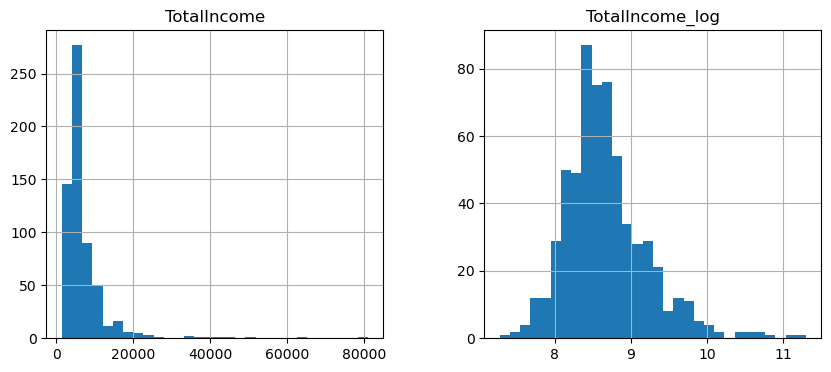

In [22]:
df[['TotalIncome', 'TotalIncome_log']].hist(bins=30, figsize=(10,4))

# Step 5: Train-Test Split

In [23]:
X = df.drop('Loan_Status', axis=1)
y = df['Loan_Status']

In [24]:
print(X.shape)
print(y.shape)

(614, 15)
(614,)


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [26]:
print(X_train.shape, X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(491, 15) (123, 15)
Loan_Status
1    337
0    154
Name: count, dtype: int64
Loan_Status
1    85
0    38
Name: count, dtype: int64


# Step 6: Training

In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [28]:
y_pred = model.predict(X_test_scaled)

In [29]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.8536585365853658


# Step 7: Proper Evaluation

In [30]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

[[22 16]
 [ 2 83]]


# Step 8: Random Forest Model

In [31]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_scaled, y_train)

RandomForestClassifier(random_state=42)

In [32]:
y_pred_rf = rf_model.predict(X_test_scaled)

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Accuracy: 0.8699186991869918
[[27 11]
 [ 5 80]]
              precision    recall  f1-score   support

           0       0.84      0.71      0.77        38
           1       0.88      0.94      0.91        85

    accuracy                           0.87       123
   macro avg       0.86      0.83      0.84       123
weighted avg       0.87      0.87      0.87       123



# step 9: Hyperparameter Tuning 

In [33]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10]
}

In [34]:
from sklearn.metrics import make_scorer, recall_score

recall_class0 = make_scorer(recall_score, pos_label=0)

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring=recall_class0,
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

print(grid_search.best_params_)
print(grid_search.best_score_)

{'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
0.44150537634408604


In [35]:
best_rf = RandomForestClassifier(
    max_depth=None,
    min_samples_split=5,
    n_estimators=200,
    random_state=42
)
best_rf.fit(X_train_scaled, y_train)

y_pred_best = best_rf.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_best))
print(confusion_matrix(y_test, y_pred_best))
print(classification_report(y_test, y_pred_best))

Accuracy: 0.8617886178861789
[[27 11]
 [ 6 79]]
              precision    recall  f1-score   support

           0       0.82      0.71      0.76        38
           1       0.88      0.93      0.90        85

    accuracy                           0.86       123
   macro avg       0.85      0.82      0.83       123
weighted avg       0.86      0.86      0.86       123



# GradientBoosting

In [36]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train_scaled, y_train)

GradientBoostingClassifier(random_state=42)

In [37]:
y_pred_gb = gb_model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print(confusion_matrix(y_test, y_pred_gb))
print(classification_report(y_test, y_pred_gb))

Accuracy: 0.8373983739837398
[[24 14]
 [ 6 79]]
              precision    recall  f1-score   support

           0       0.80      0.63      0.71        38
           1       0.85      0.93      0.89        85

    accuracy                           0.84       123
   macro avg       0.82      0.78      0.80       123
weighted avg       0.83      0.84      0.83       123



# smote

In [38]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

In [39]:
print(y_train.value_counts())
print(y_train_smote.value_counts())

Loan_Status
1    337
0    154
Name: count, dtype: int64
Loan_Status
1    337
0    337
Name: count, dtype: int64


In [40]:
rf_smote = RandomForestClassifier(random_state=42)
rf_smote.fit(X_train_smote, y_train_smote)

y_pred_smote = rf_smote.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_smote))
print(confusion_matrix(y_test, y_pred_smote))
print(classification_report(y_test, y_pred_smote))

Accuracy: 0.8292682926829268
[[26 12]
 [ 9 76]]
              precision    recall  f1-score   support

           0       0.74      0.68      0.71        38
           1       0.86      0.89      0.88        85

    accuracy                           0.83       123
   macro avg       0.80      0.79      0.80       123
weighted avg       0.83      0.83      0.83       123



In [41]:
rf_weighted = RandomForestClassifier(class_weight='balanced', random_state=42)
rf_weighted.fit(X_train_scaled, y_train)

y_pred_weighted = rf_weighted.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_weighted))
print(confusion_matrix(y_test, y_pred_weighted))
print(classification_report(y_test, y_pred_weighted))

Accuracy: 0.8373983739837398
[[24 14]
 [ 6 79]]
              precision    recall  f1-score   support

           0       0.80      0.63      0.71        38
           1       0.85      0.93      0.89        85

    accuracy                           0.84       123
   macro avg       0.82      0.78      0.80       123
weighted avg       0.83      0.84      0.83       123



# Feature Importance

In [42]:
import pandas as pd

importances = pd.Series(rf_model.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)
print(importances)

Credit_History             0.220946
ApplicantIncome            0.121962
TotalIncome                0.114137
TotalIncome_log            0.108115
LoanAmount_log             0.096740
LoanAmount                 0.092620
CoapplicantIncome          0.066661
Dependents                 0.036496
Loan_Amount_Term           0.035609
Property_Area_Semiurban    0.022964
Education                  0.020856
Property_Area_Urban        0.017756
Married                    0.016336
Self_Employed              0.014641
Gender                     0.014159
dtype: float64


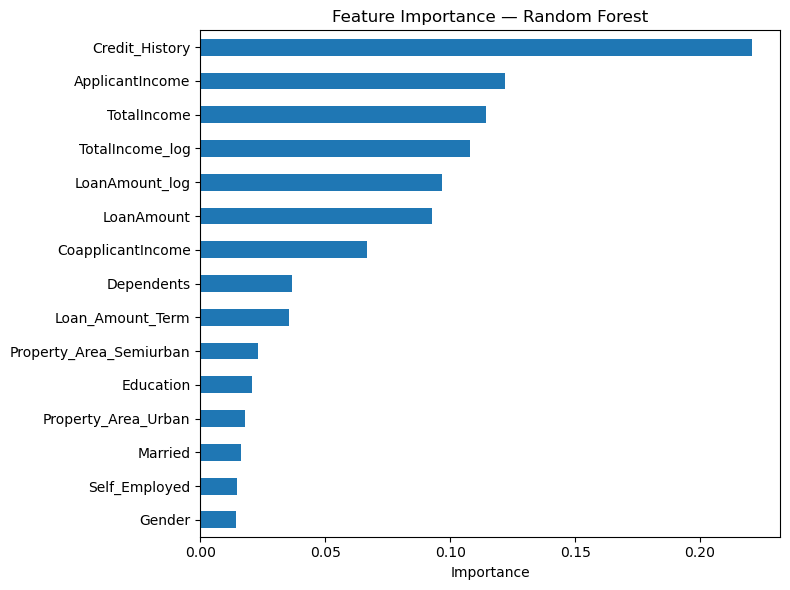

In [43]:
import matplotlib.pyplot as plt

importances.plot(kind='barh', figsize=(8,6))
plt.gca().invert_yaxis()
plt.xlabel('Importance')
plt.title('Feature Importance — Random Forest')
plt.tight_layout()
plt.show()

# Target Distribution

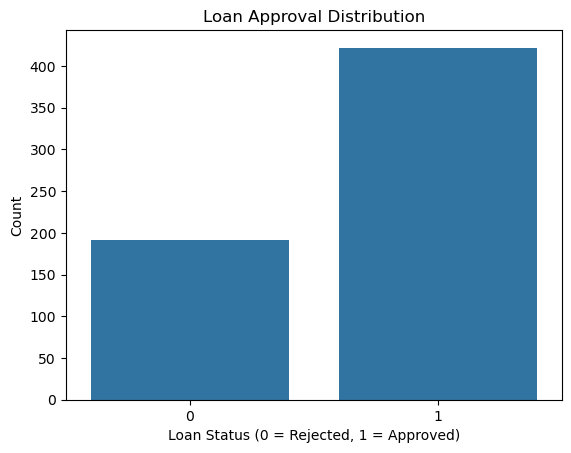

In [44]:
import seaborn as sns

sns.countplot(x='Loan_Status', data=df)
plt.title('Loan Approval Distribution')
plt.xlabel('Loan Status (0 = Rejected, 1 = Approved)')
plt.ylabel('Count')
plt.show()

# Correlation heatmap

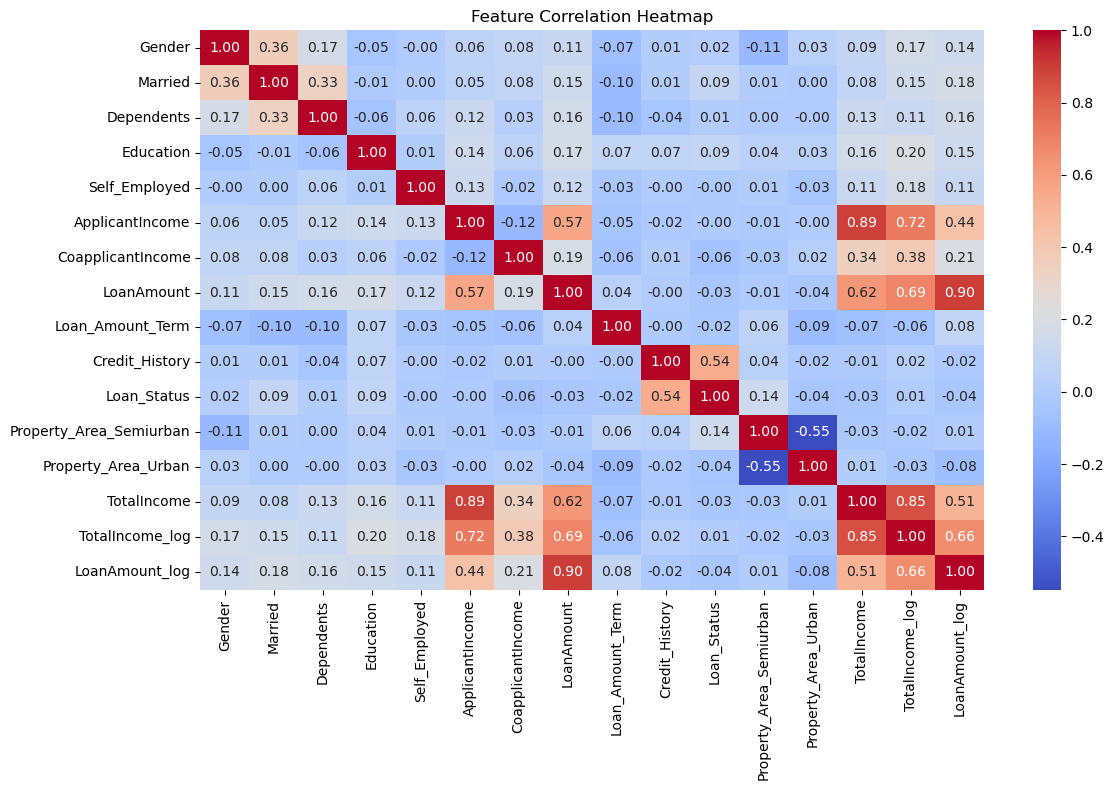

In [45]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

# Model comparison chart

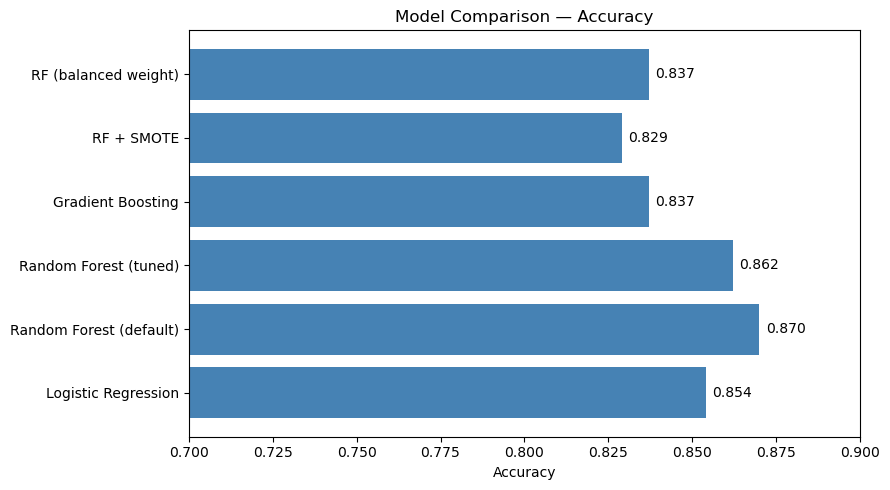

In [46]:
model_results = {
    'Logistic Regression': 0.854,
    'Random Forest (default)': 0.870,
    'Random Forest (tuned)': 0.862,
    'Gradient Boosting': 0.837,
    'RF + SMOTE': 0.829,
    'RF (balanced weight)': 0.837
}

plt.figure(figsize=(9, 5))
plt.barh(list(model_results.keys()), list(model_results.values()), color='steelblue')
plt.xlabel('Accuracy')
plt.title('Model Comparison — Accuracy')
plt.xlim(0.7, 0.9)
for i, v in enumerate(model_results.values()):
    plt.text(v + 0.002, i, f'{v:.3f}', va='center')
plt.tight_layout()
plt.show()

In [47]:
import joblib

joblib.dump(rf_model, 'loan_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

In [48]:
import os
print(os.listdir())

['.anaconda', '.arduinoIDE', '.conda', '.condarc', '.config', '.continuum', '.copilot', '.dbclient', '.eclipse', '.gitconfig', '.gradle', '.ipynb_checkpoints', '.ipython', '.jupyter', '.m2', '.matplotlib', '.ms-ad', '.p2', '.packettracer', '.python_history', '.sts4', '.vscode', 'AppData', 'Application Data', 'BAGGING.ipynb', 'cd', 'Cisco Packet Tracer 9.0.0', 'CLIManagementPortal', 'Contacts', 'Cookies', 'Customer_Preprocessing.ipynb', 'CV k-fold.ipynb', 'Documents', 'Downloads', 'eclipse-workspace', 'Favorites', 'graph.ipynb', 'GRID SEARCH.ipynb', 'hospital management', 'Links', 'loan_model.pkl', 'Local Settings', 'logs.log', 'Lone_Approval_Prediction.ipynb', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{e3025583-c2b1-11ef-adb3-60ff9ebb9115}.TM.blf', 'NTUSER.DAT{e3025583-c2b1-11ef-adb3-60ff9ebb9115}.TM.blf.cnpf', 'NTUSER.DAT{e3025583-c2b1-11ef-adb3-60ff9ebb9115}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{e3025583-c2b

In [49]:
!pip install --user --no-cache-dir streamlit

Access is denied.


In [50]:
import streamlit
print(streamlit.__version__)

1.45.1


In [51]:
print(list(X.columns))

['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area_Semiurban', 'Property_Area_Urban', 'TotalIncome', 'TotalIncome_log', 'LoanAmount_log']


In [52]:
import os
print(os.listdir())

['.anaconda', '.arduinoIDE', '.conda', '.condarc', '.config', '.continuum', '.copilot', '.dbclient', '.eclipse', '.gitconfig', '.gradle', '.ipynb_checkpoints', '.ipython', '.jupyter', '.m2', '.matplotlib', '.ms-ad', '.p2', '.packettracer', '.python_history', '.sts4', '.vscode', 'app.py', 'AppData', 'Application Data', 'BAGGING.ipynb', 'cd', 'Cisco Packet Tracer 9.0.0', 'CLIManagementPortal', 'Contacts', 'Cookies', 'Customer_Preprocessing.ipynb', 'CV k-fold.ipynb', 'Documents', 'Downloads', 'eclipse-workspace', 'Favorites', 'graph.ipynb', 'GRID SEARCH.ipynb', 'hospital management', 'Links', 'loan_model.pkl', 'Local Settings', 'logs.log', 'Lone_Approval_Prediction.ipynb', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{e3025583-c2b1-11ef-adb3-60ff9ebb9115}.TM.blf', 'NTUSER.DAT{e3025583-c2b1-11ef-adb3-60ff9ebb9115}.TM.blf.cnpf', 'NTUSER.DAT{e3025583-c2b1-11ef-adb3-60ff9ebb9115}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{e3